# Heterogeneous Evolution Strategies for Mixed-Variable Optimization

## Experiment 1: Equal-Budget Benchmark Comparison

> Prototype 1 vs Baseline Optimizers (Isotropic ES and CMA-ES)

> This notebook compares Prototype 1 (our custom heterogeneous ES model) against the following baseline implementations:
1. **Isotropic ES (Simple Self-Adaptive)**: Uses a single global $\sigma$ ($n_\sigma = 1$, $n_\alpha = 0$).
2. **sep-CMA-ES (Separable CMA-ES)**: Diagonal CMA-ES from the `pycma` library (`CMA_diagonal=True`).
3. **Standard CMA-ES (Upper Bound)**: Full-covariance CMA-ES used strictly as a performance ceiling.

All comparisons use the **real-valued block only** for fairness, evaluated on
standard benchmark functions with equal evaluation budgets and 10 seeds.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import sys, os
import cma

# Add project root to path so we can import project packages
sys.path.insert(0, os.path.abspath('..'))
from src.es_model.config import ESConfig
from src.es_model import kernels
from src.es_model.engine import Individual, HeterogeneousES, create_random_individual, clone_individual, mutate_individual, select_survivors
from src.benchmarks.functions import BENCHMARKS
from src.runners import custom_es, isotropic_es, sep_cma_es, standard_cma_es

## 2. Benchmark Functions

Each function accepts a 1-D numpy array of shape `(n,)` and returns a scalar.
Global minimum is 0.0 at the origin (or known point) for all functions.

In [10]:
# BENCHMARKS is imported from src.benchmarks.functions
print(f"Loaded {len(BENCHMARKS)} benchmark definitions from src.benchmarks")

Loaded 4 benchmark definitions from src.benchmarks


In [11]:
# --- Verify global minima ---
DIM = 2
for name, info in BENCHMARKS.items():
    x_opt = info['optimum'](DIM)
    val = info['fn'](x_opt)
    assert abs(val) < 1e-10, f"{name} failed: f(optimum) = {val}"
    print(f"  {name:12s} f(optimum) = {val:.2e} ✓")
print("\nAll benchmark functions verified.")

  Sphere       f(optimum) = 0.00e+00 ✓
  Rastrigin    f(optimum) = 0.00e+00 ✓
  Rosenbrock   f(optimum) = 0.00e+00 ✓
  Ackley       f(optimum) = 4.44e-16 ✓

All benchmark functions verified.


## 3. Runner Wrappers & Experiment Execution

Each runner is imported from `src.runners` and implements the standard interface:
`run(fn, dim, bounds, seed, max_evals, **kwargs) -> np.ndarray`
returning a 1-D array of best-fitness values indexed by evaluation count.

We configure and run all baseline optimizers and Prototype 1 across all benchmark functions.

In [ ]:
# Experiment parameters
DIM = 10
MAX_EVALS = 10_000
N_SEEDS = 10
SEEDS = list(range(1, N_SEEDS + 1))


# --- All runners registry ---
RUNNERS = {
    'Prototype 1':                          custom_es.run,
    'Isotropic ES (Simple Self-Adaptive)':  isotropic_es.run,
    'sep-CMA-ES (Separable CMA-ES)':        sep_cma_es.run,
    'Standard CMA-ES (Upper Bound)':        standard_cma_es.run,
}

In [ ]:
def run_all_experiments(benchmarks, runners, dim, max_evals, seeds):
    results = {}
    for bname, binfo in benchmarks.items():
        results[bname] = {}
        b_dim = binfo.get("dim", dim)
        for rname, runner in runners.items():
            traces = []
            for seed in seeds:
                if rname == "Prototype 1":
                    proto_config = ESConfig(
                        n_real=b_dim,
                        n_count=0,
                        n_binary=0,
                        n_categorical=0,
                        n_fuzzy=0,
                        lower_bound_real=float(binfo["bounds"][0]),
                        upper_bound_real=float(binfo["bounds"][1]),
                        seed=seed,
                    )
                    trace = runner(binfo["fn"], b_dim, binfo["bounds"], seed, max_evals, config=proto_config)
                else:
                    trace = runner(binfo["fn"], b_dim, binfo["bounds"], seed, max_evals)
                traces.append(trace)
            results[bname][rname] = np.array(traces)
            median_final = np.median(results[bname][rname][:, -1])
            print(f"  {bname:12s} | {rname:36s} | median final: {median_final:.4e}")
    return results

print("Running experiments...\n")
results = run_all_experiments(BENCHMARKS, RUNNERS, DIM, MAX_EVALS, SEEDS)
print("\nAll experiments complete.")


Running experiments...

  Sphere       | Prototype 1                          | median final: 2.4952e-12
  Sphere       | Isotropic ES (Simple Self-Adaptive)  | median final: 2.5641e-10
  Sphere       | sep-CMA-ES (Separable CMA-ES)        | median final: 7.5449e-15
  Sphere       | Standard CMA-ES (Upper Bound)        | median final: 1.6433e-14
  Rastrigin    | Prototype 1                          | median final: 1.9975e+00
  Rastrigin    | Isotropic ES (Simple Self-Adaptive)  | median final: 4.3281e+01
  Rastrigin    | sep-CMA-ES (Separable CMA-ES)        | median final: 1.3432e+01
  Rastrigin    | Standard CMA-ES (Upper Bound)        | median final: 1.4924e+01
  Rosenbrock   | Prototype 1                          | median final: 7.2198e+00
  Rosenbrock   | Isotropic ES (Simple Self-Adaptive)  | median final: 7.1741e+00
  Rosenbrock   | sep-CMA-ES (Separable CMA-ES)        | median final: 1.0475e+00
  Rosenbrock   | Standard CMA-ES (Upper Bound)        | median final: 2.9543e-14
  Ac

## 4. Visualization

For each benchmark function, we plot:
1. **2D Function Landscape (Surface Contour Plot)**: Compact contour map of $f(x_1, x_2)$ showing topologic features (multimodality, steepness, valleys) and the global optimum ($\star$).
2. **Convergence Trajectory**: Median best-so-far fitness over evaluations with IQR (25th–75th percentile) envelope across 10 random seeds in $D=10$.

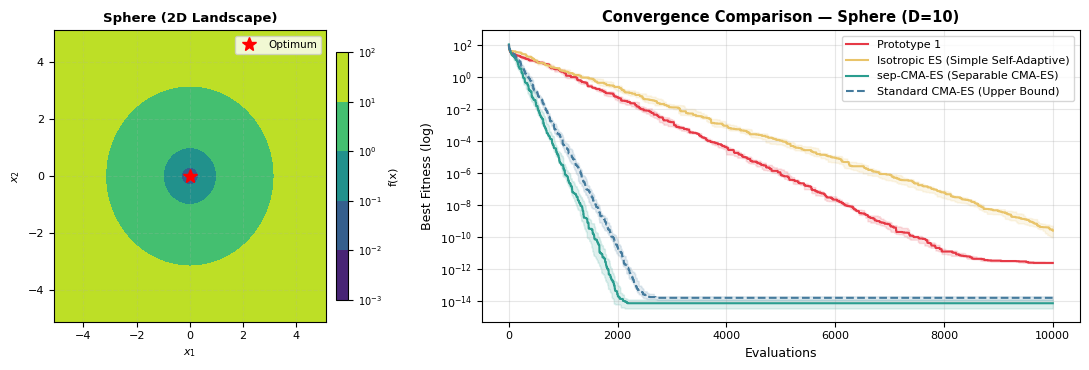

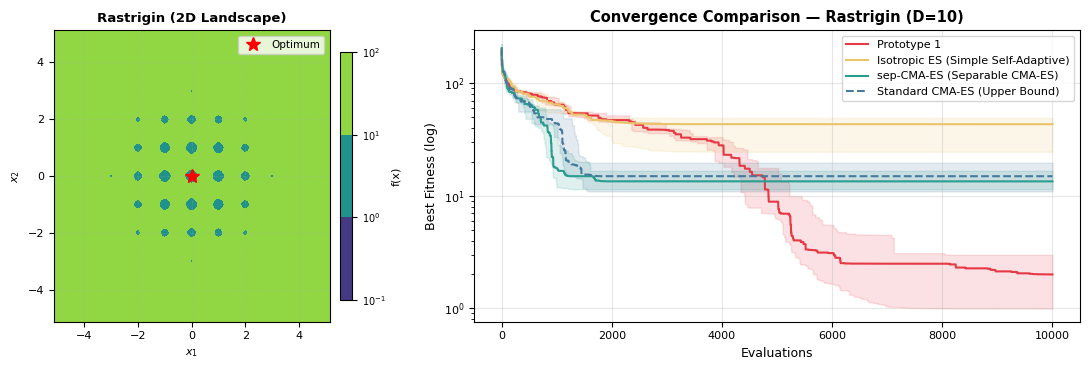

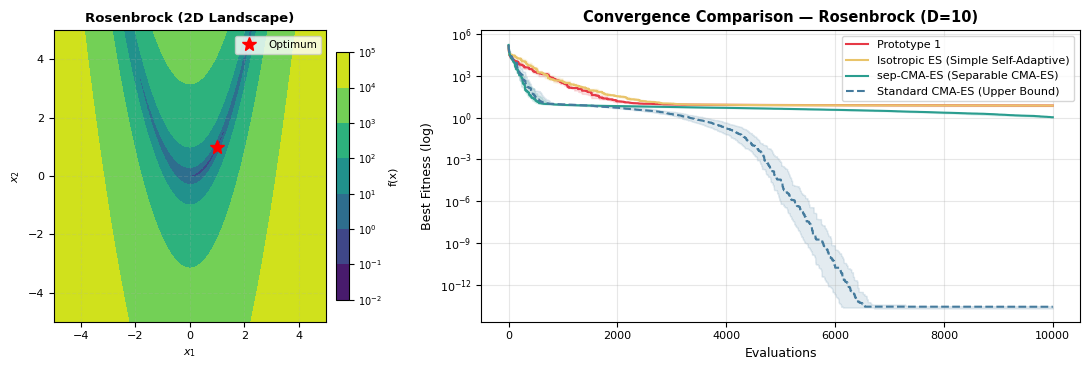

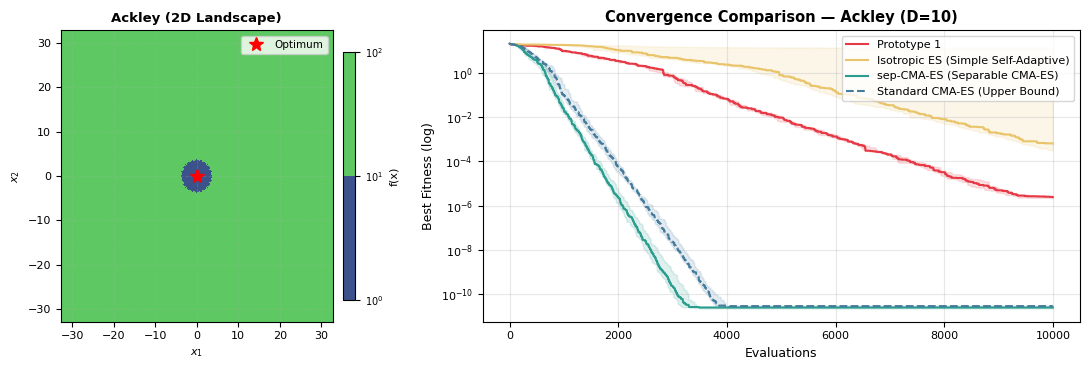

In [24]:
from matplotlib.colors import LogNorm

COLORS = {
    'Prototype 1':                          '#E63946',
    'Isotropic ES (Simple Self-Adaptive)':  '#E9C46A',
    'sep-CMA-ES (Separable CMA-ES)':        '#2A9D8F',
    'Standard CMA-ES (Upper Bound)':        '#457B9D',
}


def plot_benchmark_summary(bname: str, binfo: dict, data: dict, max_evals: int) -> None:
    """
    Plot side-by-side with asymmetric width ratios:
      Left:  Compact 2D Function Landscape (Contour Plot).
      Right: Main Convergence Trajectories curve.
    """
    fig, (ax_surf, ax_conv) = plt.subplots(
        1, 2, 
        figsize=(11, 3.8), 
        gridspec_kw={'width_ratios': [1, 1.8]}
    )
    
    # -------------------------------------------------------------
    # 1. Left Panel: Compact 2D Contour Plot of Benchmark Function
    # -------------------------------------------------------------
    bounds = binfo['bounds']
    x = np.linspace(bounds[0], bounds[1], 150)
    y = np.linspace(bounds[0], bounds[1], 150)
    X, Y = np.meshgrid(x, y)
    
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = binfo['fn'](np.array([X[i, j], Y[i, j]]))
            
    Z_min = Z.min()
    Z_shift = Z - Z_min + 1e-6 if Z_min <= 0 else Z
    
    cs = ax_surf.contourf(X, Y, Z_shift, levels=25, cmap='viridis', norm=LogNorm())
    cbar = fig.colorbar(cs, ax=ax_surf, pad=0.03, shrink=0.85)
    cbar.set_label('f(x)', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    opt = binfo['optimum'](2)
    ax_surf.plot(opt[0], opt[1], 'r*', markersize=10, label='Optimum', zorder=5)
    ax_surf.set_title(f'{bname} (2D Landscape)', fontsize=9.5, fontweight='bold')
    ax_surf.set_xlabel('$x_1$', fontsize=8)
    ax_surf.set_ylabel('$x_2$', fontsize=8)
    ax_surf.tick_params(labelsize=8)
    ax_surf.grid(True, alpha=0.2, linestyle='--')
    ax_surf.legend(loc='upper right', fontsize=7.5)
    
    # -------------------------------------------------------------
    # 2. Right Panel: Convergence Trajectories
    # -------------------------------------------------------------
    evals = np.arange(1, max_evals + 1)

    for rname, traces in data.items():
        median = np.median(traces, axis=0)
        q25 = np.percentile(traces, 25, axis=0)
        q75 = np.percentile(traces, 75, axis=0)

        color = COLORS.get(rname, '#888888')
        ls = '--' if 'Upper Bound' in rname else '-'
        ax_conv.plot(evals, median, label=rname, color=color, linewidth=1.5, linestyle=ls)
        ax_conv.fill_between(evals, q25, q75, alpha=0.15, color=color)

    ax_conv.set_yscale('log')
    ax_conv.set_xlabel('Evaluations', fontsize=9)
    ax_conv.set_ylabel('Best Fitness (log)', fontsize=9)
    ax_conv.set_title(f'Convergence Comparison — {bname} (D=10)', fontsize=10.5, fontweight='bold')
    ax_conv.legend(loc='upper right', fontsize=8)
    ax_conv.grid(True, alpha=0.3)
    ax_conv.tick_params(labelsize=8)
    
    plt.tight_layout()
    plt.show()
